# Анализ метеорологических наблюдений и температуры поверхности океана

**Выполнение заданий 1 и 2 в Python**

**Краткие результаты.** В `September.xlsx` содержатся 120 измерений за **1-15 сентября 2021 г.** с периодичностью 3 часа. Температура воздуха: **4,9...19,7 °C**, атмосферное давление: **746,9...765,8** (предположительно мм рт. ст.). Файл `sst.nc` описывает температуру поверхности Мирового океана за **1 сентября 1981 г.**, на сетке **0,25°**. Данные SST хранятся **в градусах Цельсия**, а не в кельвинах, поэтому дополнительное вычитание 273,15 не выполняется.

**Результат:** временные ряды двух метеорологических характеристик, глобальная карта SST и карта северо-западной части Тихого океана (20-60° с. ш., 120-180° в. д.). Все рисунки сохраняются в папке `figures/`.

> Источники относятся к разным годам (1981 и 2021) и не должны интерпретироваться как синхронные наблюдения.

## 0. Подготовка среды

Поместите `September.xlsx`, `sst.nc` и этот ноутбук **в одну папку**. Выполняйте ячейки сверху вниз.

Используемые библиотеки: `numpy`, `pandas`, `openpyxl` (движок чтения Excel), `h5py`, `matplotlib`. `basemap` необязателен: с ним будут нанесены береговые линии и суша. Без него сами карты температуры также строятся.

Пример установки: `pip install numpy pandas openpyxl h5py matplotlib basemap`.

In [1]:
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from IPython.display import display

try:
    from mpl_toolkits.basemap import Basemap
except ImportError:
    Basemap = None

excel_path = Path("September.xlsx")
netcdf_path = Path("sst.nc")
output_dir = Path("figures")
output_dir.mkdir(parents=True, exist_ok=True)

for path in [excel_path, netcdf_path]:
    if not path.is_file():
        raise FileNotFoundError(f"Не найден файл {path}. Разместите его рядом с ноутбуком.")

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 110,
    "savefig.dpi": 180,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print("Файлы найдены. Basemap доступен:", Basemap is not None)

Файлы найдены. Basemap доступен: True


## Задание 1. Временной ход температуры воздуха и давления

Таблица Excel содержит столбцы `Time`, `Temperature`, `Pressure`. Для корректного временного хода сортируем записи **по возрастанию времени**, так как исходный лист расположен в обратном порядке.

**Предположения об единицах:** в таблице Excel единицы измерения явно не указаны. Температуру обозначаем в °C, давление в мм рт. ст. исходя из характерного диапазона значений около 760. Для строгой интерпретации их следует сверить с источником измерений.

In [2]:
weather = pd.read_excel(excel_path, sheet_name=0)
required_columns = ["Time", "Temperature", "Pressure"]
if not set(required_columns).issubset(weather.columns):
    raise ValueError(f"Ожидались столбцы: {required_columns}. Доступны: {list(weather.columns)}")
weather = weather[required_columns].copy()

# Excel может вернуть и готовые даты, и числовые последовательные даты.
if pd.api.types.is_numeric_dtype(weather["Time"]):
    weather["Time"] = pd.to_datetime(weather["Time"], unit="D", origin="1899-12-30")
else:
    weather["Time"] = pd.to_datetime(weather["Time"], errors="raise")

for col in ["Temperature", "Pressure"]:
    weather[col] = pd.to_numeric(weather[col], errors="coerce")
weather = weather.dropna(subset=required_columns).sort_values("Time").reset_index(drop=True)

print(f"Измерений: {len(weather)}")
print(f"Временной интервал: {weather['Time'].min():%d.%m.%Y %H:%M} - "
      f"{weather['Time'].max():%d.%m.%Y %H:%M}")
display(weather.head(6))

Измерений: 120
Временной интервал: 01.09.2021 00:00 - 15.09.2021 21:00


,Time,Temperature,Pressure
0,2021-09-01 00:00:00,10.0,758.5
1,2021-09-01 03:00:00,9.2,757.3
2,2021-09-01 06:00:00,10.7,755.9
3,2021-09-01 09:00:00,13.5,755.3
4,2021-09-01 12:00:00,16.7,754.9
5,2021-09-01 15:00:00,17.0,754.5


In [3]:
weather_summary = weather[["Temperature", "Pressure"]].agg(["min", "max", "mean", "std"]).T
weather_summary.index = ["Температура воздуха, °C*", "Давление, мм рт. ст.*"]
display(weather_summary.round(2))

step_hours = weather["Time"].diff().dropna().dt.total_seconds() / 3600
print("Шаг измерений (часов):", sorted(step_hours.unique()))
assert len(weather) > 1 and (step_hours > 0).all()

,min,max,mean,std
"Температура воздуха, °C*",4.9,19.7,11.95,3.26
"Давление, мм рт. ст.*",746.9,765.8,758.28,4.65


Шаг измерений (часов): [np.float64(3.0)]


### 1.1. Линейные графики во времени

Для величин с разными единицами измерения используются две синхронизированные панели и общая ось времени.

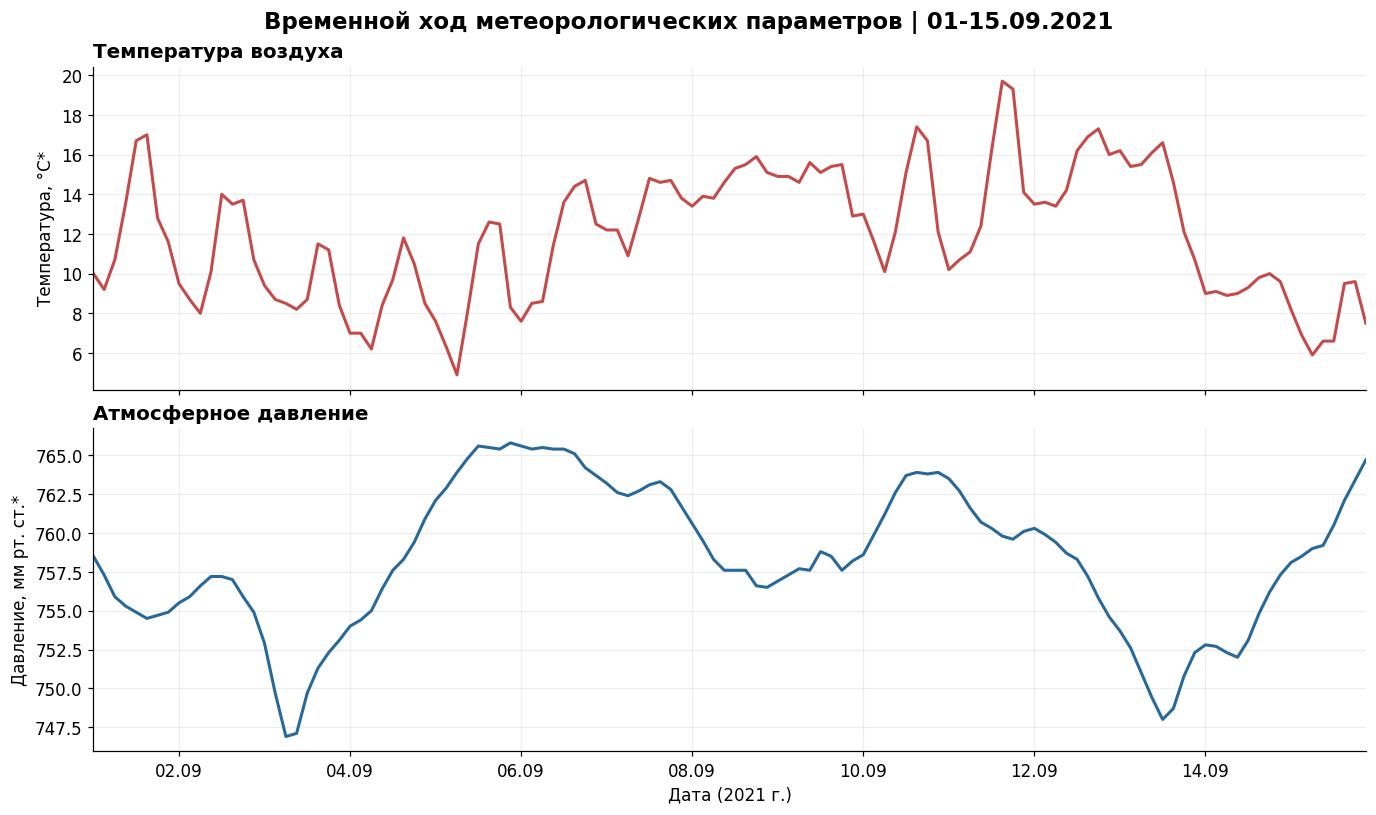

* Единицы не указаны в источнике Excel; использованы предположения по диапазонам.


In [4]:
fig, (ax_temp, ax_press) = plt.subplots(
    2, 1, figsize=(12.4, 7.3), sharex=True,
    gridspec_kw={"height_ratios": [1, 1]}, constrained_layout=True,
)

ax_temp.plot(weather["Time"], weather["Temperature"], color="#C54B4B", lw=2.0)
ax_temp.set_ylabel("Температура, °C*")
ax_temp.set_title("Температура воздуха", loc="left", fontweight="bold")
ax_temp.grid(True, alpha=0.22)

ax_press.plot(weather["Time"], weather["Pressure"], color="#28699A", lw=2.0)
ax_press.set_ylabel("Давление, мм рт. ст.*")
ax_press.set_title("Атмосферное давление", loc="left", fontweight="bold")
ax_press.grid(True, alpha=0.22)
ax_press.set_xlabel("Дата (2021 г.)")
ax_press.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax_press.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
ax_press.set_xlim(weather["Time"].min(), weather["Time"].max())

fig.suptitle("Временной ход метеорологических параметров | 01-15.09.2021",
             fontsize=15, fontweight="bold")
fig.savefig(output_dir / "01_weather_timeseries.png", bbox_inches="tight")
plt.show()
print("* Единицы не указаны в источнике Excel; использованы предположения по диапазонам.")

## Задание 2. Горизонтальное распределение температуры поверхности моря

`sst.nc` имеет формат **NetCDF-4/HDF5**. Читаем его через `h5py`: это позволяет получить переменные, размерности, атрибуты, масштабирование и пропуски даже без установленных `netCDF4` и `h5netcdf`.

Для `sst` исходные целочисленные значения преобразуются по метаданным файла:

\[
T_\mathrm{phys}=T_\mathrm{raw}\cdot\mathrm{scale\_factor}+\mathrm{add\_offset}.
\]

Недостоверные значения и `_FillValue` маскируются до построения карты.

In [5]:
def attr_text(value):
    """Преобразовать одиночный HDF5-атрибут в текст."""
    if isinstance(value, np.ndarray) and value.size == 1:
        value = value.item()
    if isinstance(value, (bytes, np.bytes_)):
        return value.decode("utf-8", errors="replace")
    return str(value)


def dimension_names(dataset, dataset_name):
    """Получить имена измерений из NetCDF-4/HDF5 dimension scales."""
    names = []
    for axis in range(dataset.ndim):
        scales = list(dataset.dims[axis].keys())
        names.append(scales[0] if scales else (dataset_name if dataset.ndim == 1 else f"dim_{axis}"))
    return tuple(names)

with h5py.File(netcdf_path, "r") as nc:
    overview = []
    for name, ds in nc.items():
        if not isinstance(ds, h5py.Dataset):
            continue
        overview.append({
            "Переменная": name,
            "Размерности": ", ".join(dimension_names(ds, name)),
            "Форма": " × ".join(map(str, ds.shape)),
            "Единицы": attr_text(ds.attrs["units"]) if "units" in ds.attrs else "не указаны",
        })
    print("Название набора данных:", attr_text(nc.attrs.get("title", "нет названия")))
    print("Переменные и размерности:")
    display(pd.DataFrame(overview))
    print("Размерности SST:", dimension_names(nc["sst"], "sst"))
    print("Единицы SST в исходном файле:", attr_text(nc["sst"].attrs["units"]))

Название набора данных: NOAA/NCEI 1/4 Degree Daily Optimum Interpolation Sea Surface Temperature (OISST) Analysis, Version 2.1 - Final
Переменные и размерности:


,Переменная,Размерности,Форма,Единицы
0,anom,"time, zlev, lat, lon",1 × 1 × 720 × 1440,Celsius
1,err,"time, zlev, lat, lon",1 × 1 × 720 × 1440,Celsius
2,ice,"time, zlev, lat, lon",1 × 1 × 720 × 1440,%
3,lat,lat,720,degrees_north
4,lon,lon,1440,degrees_east
5,sst,"time, zlev, lat, lon",1 × 1 × 720 × 1440,Celsius
6,time,time,1,days since 1978-01-01 12:00:00
7,zlev,zlev,1,meters


Размерности SST: ('time', 'zlev', 'lat', 'lon')
Единицы SST в исходном файле: Celsius


### 2.1. Чтение поля SST, применение scale factor и проверка единиц

**Правило конвертации:** если поле задано в кельвинах, применяем \(T_{°C}=T_K-273{,}15\). Если оно уже в градусах Цельсия, оставляем без изменения. В данном файле выполняется второй вариант.

In [6]:
with h5py.File(netcdf_path, "r") as nc:
    lat = nc["lat"][:].astype(float)
    lon = nc["lon"][:].astype(float)
    ds_sst = nc["sst"]
    raw_sst = ds_sst[0, 0, :, :]  # time=0, zlev=0; форма: (lat, lon)

    fill_value = float(np.asarray(ds_sst.attrs["_FillValue"]).item())
    scale_factor = float(np.asarray(ds_sst.attrs.get("scale_factor", [1.])).item())
    add_offset = float(np.asarray(ds_sst.attrs.get("add_offset", [0.])).item())
    valid_min = float(np.asarray(ds_sst.attrs.get("valid_min", [-np.inf])).item())
    valid_max = float(np.asarray(ds_sst.attrs.get("valid_max", [np.inf])).item())
    source_unit = attr_text(ds_sst.attrs["units"])

    # Маска строится по исходным целым кодам до масштабирования.
    invalid = (~np.isfinite(raw_sst) | (raw_sst == fill_value)
               | (raw_sst < valid_min) | (raw_sst > valid_max))
    sst_physical = np.ma.array(
        raw_sst.astype(float) * scale_factor + add_offset,
        mask=invalid,
    )

    normalized_unit = source_unit.lower().strip()
    if normalized_unit in {"k", "kelvin", "degrees_kelvin", "degree_kelvin"}:
        sst_c = sst_physical - 273.15
        conversion_note = "Выполнено преобразование K → °C: вычтено 273,15."
    elif normalized_unit in {"c", "celsius", "°c", "degc", "degree_celsius", "degrees_celsius"}:
        sst_c = sst_physical
        conversion_note = "Исходные данные уже в °C; преобразование из K не требуется."
    else:
        raise ValueError(f"Неизвестная единица температуры: {source_unit!r}")

    time_units = attr_text(nc["time"].attrs["units"])
    time_origin = datetime.strptime(time_units.split("since", 1)[1].strip(), "%Y-%m-%d %H:%M:%S")
    data_datetime = time_origin + timedelta(days=float(nc["time"][0]))
    data_date = data_datetime.strftime("%d.%m.%Y")

print("Дата поля SST:", data_date)
print("Исходные единицы:", source_unit)
print(conversion_note)
print(f"Размер SST: {sst_c.shape[0]} широт × {sst_c.shape[1]} долгот")
print(f"Пространственный шаг: Δширота={np.median(np.diff(lat)):.2f}°, "
      f"Δдолгота={np.median(np.diff(lon)):.2f}°")
print(f"Корректных океанических ячеек: {sst_c.count():,} из {sst_c.size:,}")
print(f"Диапазон температуры: {sst_c.min():.2f} ... {sst_c.max():.2f} °C")
assert sst_c.shape == (len(lat), len(lon))
assert sst_c.count() > 0

Дата поля SST: 01.09.1981
Исходные единицы: Celsius
Исходные данные уже в °C; преобразование из K не требуется.
Размер SST: 720 широт × 1440 долгот
Пространственный шаг: Δширота=0.25°, Δдолгота=0.25°
Корректных океанических ячеек: 691,150 из 1,036,800
Диапазон температуры: -1.80 ... 33.74 °C


### 2.2. Глобальная карта температуры поверхности Мирового океана

Исходная долгота задается от 0 до 360° в. д. Для глобальной карты преобразуем ее в диапазон от -180 до 180° и сортируем значения. Суша и отсутствующие значения не раскрашиваются как нулевая температура.

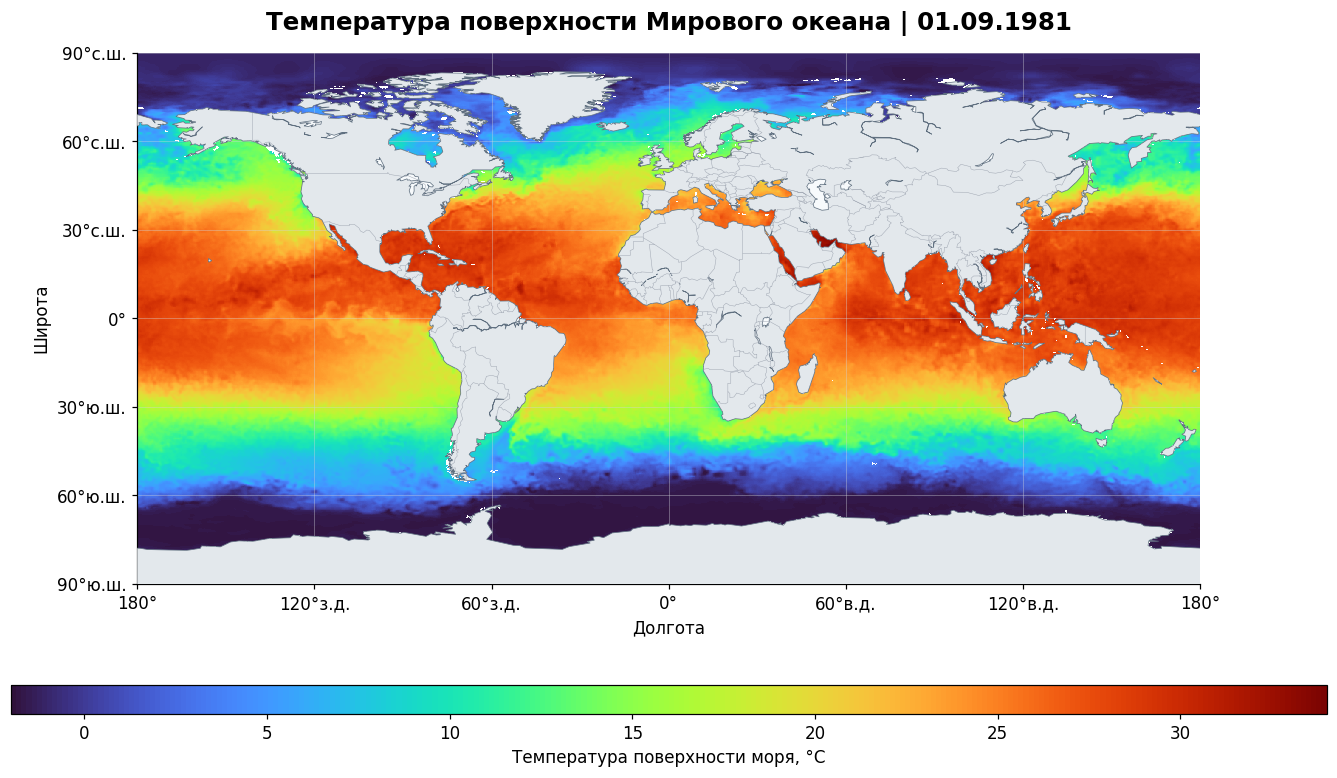

In [7]:
def longitude_label(value, _pos=None):
    if abs(value) < 1e-9:
        return "0°"
    if abs(abs(value) - 180) < 1e-9:
        return "180°"
    return f"{abs(value):g}°{'в.д.' if value > 0 else 'з.д.'}"


def latitude_label(value, _pos=None):
    if abs(value) < 1e-9:
        return "0°"
    return f"{abs(value):g}°{'с.ш.' if value > 0 else 'ю.ш.'}"


def add_basemap(ax, bounds):
    """Дорисовать берега, если установлен Basemap."""
    if Basemap is None:
        return
    left, right, bottom, top = bounds
    basemap = Basemap(
        projection="cyl", llcrnrlon=left, urcrnrlon=right,
        llcrnrlat=bottom, urcrnrlat=top, resolution="c", ax=ax,
    )
    basemap.fillcontinents(color="#E3E8EC", lake_color="#F7FAFC", zorder=3)
    basemap.drawcoastlines(color="#607080", linewidth=0.48, zorder=4)
    basemap.drawcountries(color="#9CA3AF", linewidth=0.30, zorder=4)

wrapped_lon = ((lon + 180) % 360) - 180
lon_order = np.argsort(wrapped_lon)
lon_global = wrapped_lon[lon_order]
sst_global = sst_c[:, lon_order]

fig, ax = plt.subplots(figsize=(14.2, 7.0), constrained_layout=True)
mesh = ax.pcolormesh(
    lon_global, lat, sst_global, shading="auto", cmap="turbo",
    vmin=-2, vmax=34, rasterized=True,
)
add_basemap(ax, (-180, 180, -90, 90))
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_xticks(np.arange(-180, 181, 60))
ax.set_yticks(np.arange(-90, 91, 30))
ax.xaxis.set_major_formatter(FuncFormatter(longitude_label))
ax.yaxis.set_major_formatter(FuncFormatter(latitude_label))
ax.set_xlabel("Долгота")
ax.set_ylabel("Широта")
ax.grid(color="#D1D5DB", alpha=0.5, linewidth=0.5)
ax.set_title(f"Температура поверхности Мирового океана | {data_date}",
             fontsize=16, fontweight="bold", pad=15)
cbar = fig.colorbar(mesh, ax=ax, orientation="horizontal", fraction=0.055, pad=0.085, aspect=45)
cbar.set_label("Температура поверхности моря, °C", fontsize=11)
fig.savefig(output_dir / "02_global_sst.png", bbox_inches="tight")
plt.show()

### 2.3. Региональный участок: северо-западная часть Тихого океана

**Границы:** широта **20-60° с. ш.**, долгота **120-180° в. д.** Участок включает воды у Японии, зону Куросио и более холодные северные воды. Пространственная выборка производится масками по координатам `lat` и `lon`.

In [8]:
lat_min, lat_max = 20.0, 60.0
lon_min, lon_max = 120.0, 180.0

lat_mask = (lat >= lat_min) & (lat <= lat_max)
lon_mask = (lon >= lon_min) & (lon <= lon_max)
regional_lat = lat[lat_mask]
regional_lon = lon[lon_mask]
regional_sst = sst_c[np.ix_(lat_mask, lon_mask)]

print(f"Выбранная область: {lat_min:.0f}-{lat_max:.0f}° с. ш., "
      f"{lon_min:.0f}-{lon_max:.0f}° в. д.")
print(f"Размер фрагмента: {regional_sst.shape[0]} × {regional_sst.shape[1]} точек")
print(f"Диапазон температур над водой: {regional_sst.min():.2f} ... "
      f"{regional_sst.max():.2f} °C")
assert len(regional_lat) > 0 and len(regional_lon) > 0 and regional_sst.count() > 0

Выбранная область: 20-60° с. ш., 120-180° в. д.
Размер фрагмента: 160 × 240 точек
Диапазон температур над водой: 5.46 ... 29.93 °C


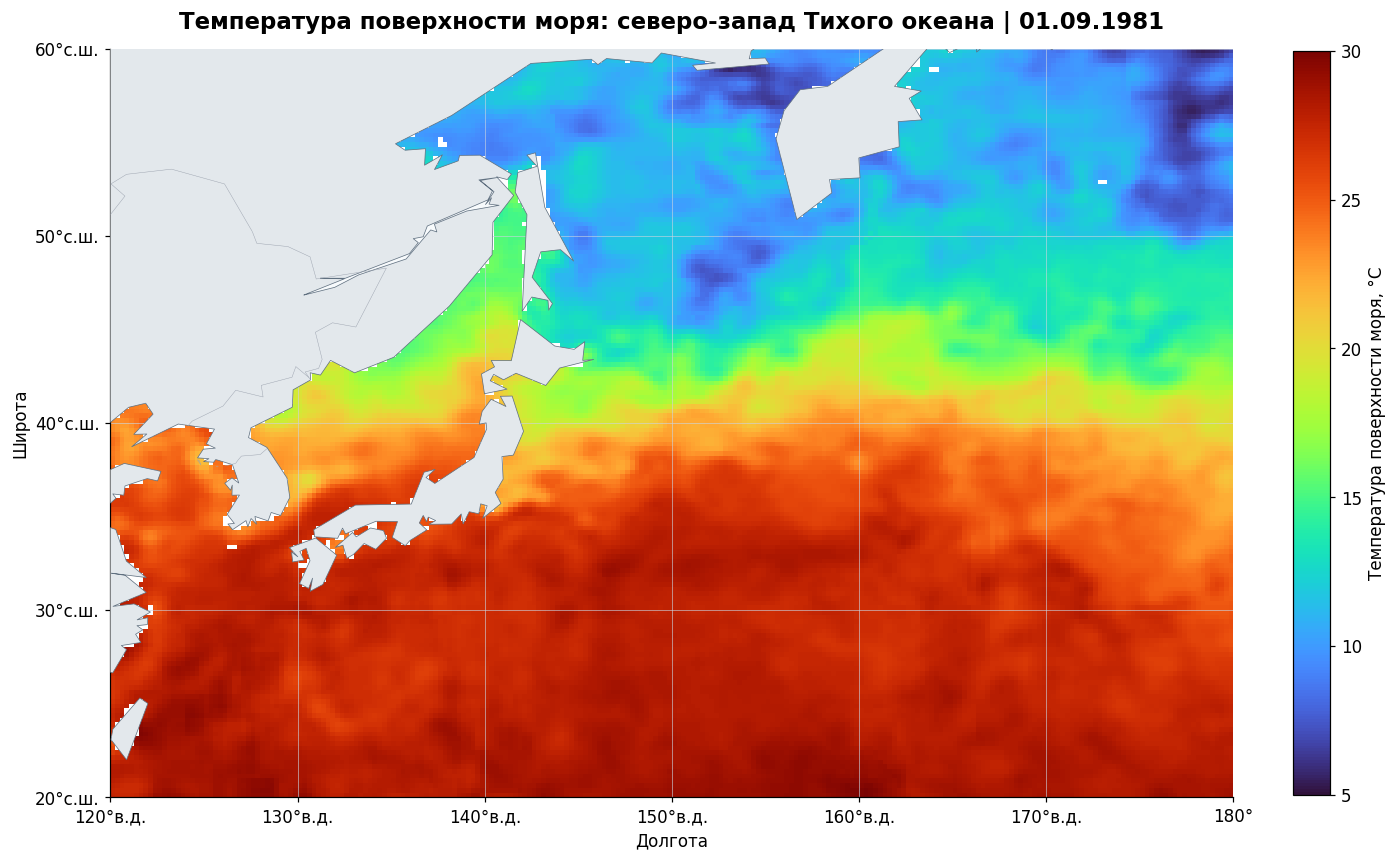

In [9]:
fig, ax = plt.subplots(figsize=(12.6, 8.0), constrained_layout=True)
mesh = ax.pcolormesh(
    regional_lon, regional_lat, regional_sst,
    shading="auto", cmap="turbo", vmin=5, vmax=30, rasterized=True,
)
add_basemap(ax, (lon_min, lon_max, lat_min, lat_max))
ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)
ax.set_xticks(np.arange(lon_min, lon_max + 1, 10))
ax.set_yticks(np.arange(lat_min, lat_max + 1, 10))
ax.xaxis.set_major_formatter(FuncFormatter(longitude_label))
ax.yaxis.set_major_formatter(FuncFormatter(latitude_label))
ax.set_xlabel("Долгота")
ax.set_ylabel("Широта")
ax.grid(color="#CBD5E1", alpha=0.6, linewidth=0.65)
ax.set_title(f"Температура поверхности моря: северо-запад Тихого океана | {data_date}",
             fontsize=15, fontweight="bold", pad=13)
cbar = fig.colorbar(mesh, ax=ax, orientation="vertical", shrink=0.86, pad=0.035)
cbar.set_label("Температура поверхности моря, °C")
fig.savefig(output_dir / "03_northwest_pacific_sst.png", bbox_inches="tight")
plt.show()

## Итог и проверка корректности

1. **Задание 1 выполнено:** данные отсортированы по времени; построены два линейных графика с датами, легенда единиц содержится в подписях осей. 120 значений с равномерным шагом 3 часа.
2. **Задание 2 выполнено:** выведены переменные, размерности, единицы; автоматически применены `scale_factor`, `add_offset` и маска пропусков; построены глобальная и региональная карты с координатами, датой и цветовой шкалой.
3. **Методологические ограничения:** единицы Excel определены предположительно, так как отсутствуют в самом листе. SST датирована 1981 г., а метеорологические наблюдения - 2021 г. На глобальной и региональной картах использованы разные пределы цветовой шкалы для повышения контрастности.
4. **Кельвины:** температура в данном `sst.nc` уже в °C. Формула пересчета из K добавлена в код и применится только при наличии соответствующих исходных единиц.

Рисунки для отдельного использования сохраняются в `figures/01_weather_timeseries.png`, `figures/02_global_sst.png`, `figures/03_northwest_pacific_sst.png`.

In [10]:
expected_plots = [
    output_dir / "01_weather_timeseries.png",
    output_dir / "02_global_sst.png",
    output_dir / "03_northwest_pacific_sst.png",
]
assert all(plot.is_file() for plot in expected_plots)
assert set(np.unique(step_hours)) == {3.0}, "Интервал измерений оказался неравномерным"
print("Проверки пройдены. Созданы рисунки:")
for plot in expected_plots:
    print(" -", plot.as_posix())

Проверки пройдены. Созданы рисунки:
 - figures/01_weather_timeseries.png
 - figures/02_global_sst.png
 - figures/03_northwest_pacific_sst.png
